In [26]:
! pip install -q numpy pandas matplotlib statsmodels scikit-learn ISLP

## Question 6

We will now explore (6.12) and (6.13) further.

**(a)** Consider (6.12) with $p = 1$. For some choice of $y_1$ and $\lambda > 0$, plot (6.12) as a function of $\beta_1$. Your plot should confirm that (6.12) is solved by (6.14).

**(b)** Consider (6.13) with $p = 1$. For some choice of $y_1$ and $\lambda > 0$, plot (6.13) as a function of $\beta_1$. Your plot should confirm that (6.13) is solved by (6.15).

### (a) 解答

根據課本公式 (6.12)，當 $p=1$ 時，Ridge Regression 的目標函數為：

$$
f(\beta_1)=(y_1-\beta_1)^2+\lambda\beta_1^2
$$

其中 $\lambda>0$ 為正則化參數。

設定：

$$
y_1=3,\qquad \lambda=2
$$

代入目標函數：

$$
\begin{aligned}
f(\beta_1)
&=(3-\beta_1)^2+2\beta_1^2\\
&=9-6\beta_1+\beta_1^2+2\beta_1^2\\
&=3\beta_1^2-6\beta_1+9
\end{aligned}
$$

對 $\beta_1$ 進行一階微分等於零二階導數大於零：

$$
\frac{\partial f(\beta_1)}{\partial\beta_1}
=6\beta_1-6
=0
$$

$$
\frac{\partial^2 f(\beta_1)}{\partial\beta_1^2}=6>0
$$

因此：

$$
\boxed{\hat{\beta}_1=1}
$$

因此，$\beta_1=1$ 為目標函數的唯一最小值位置。

根據課本公式 (6.14)，Ridge Regression 的係數估計值為：

$$
\hat{\beta}_1^R=\frac{y_1}{1+\lambda}
$$

代入設定的參數：

$$
\hat{\beta}_1^R=\frac{3}{1+2}=1
$$

因此：

$$
\boxed{\hat{\beta}_1^R=1}
$$

此結果與微分求得的最佳解完全一致。

由圖形可觀察到，目標函數呈現開口向上的拋物線，其最低點位於：

$$
(\beta_1,f(\beta_1))=(1,6)
$$

由於圖形最低點對應的係數估計值為 $\beta_1=1$，與公式 (6.14) 計算的結果相同，因此成功驗證課本的 Ridge Regression 解析解。

$$
\boxed{\hat{\beta}_1^R=\frac{y_1}{1+\lambda}=1}
$$


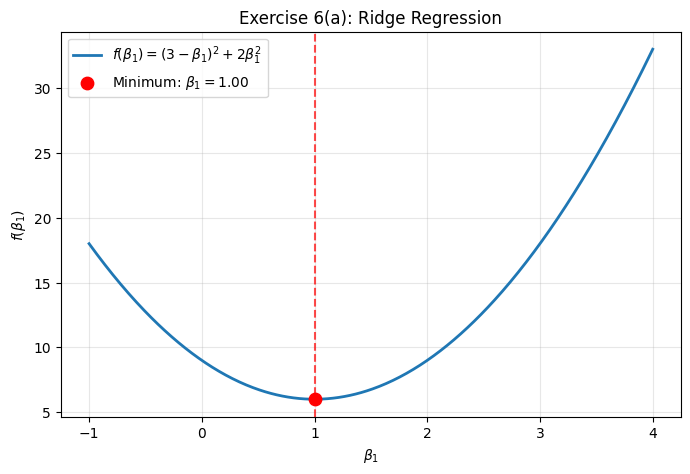

Optimal beta1 = 1.0000
Minimum objective value = 6.0000


In [27]:
import numpy as np
import matplotlib.pyplot as plt

y1 = 3
lam = 2
beta1 = np.linspace(-1, 4, 500)


objective = (y1 - beta1)**2 + lam * beta1**2

# 公式 (6.14)
beta1_hat = y1 / (1 + lam)

# 計算最小目標函數值
minimum = (y1 - beta1_hat)**2 + lam * beta1_hat**2

# 繪圖
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    beta1,
    objective,
    linewidth=2,
    label=r"$f(\beta_1)=(3-\beta_1)^2+2\beta_1^2$"
)

# 標示最小值
ax.scatter(
    beta1_hat,
    minimum,
    color="red",
    s=80,
    zorder=3,
    label=fr"Minimum: $\beta_1={beta1_hat:.2f}$"
)

# 畫出最佳解的垂直參考線
ax.axvline(
    beta1_hat,
    color="red",
    linestyle="--",
    alpha=0.7
)

ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel(r"$f(\beta_1)$")
ax.set_title("Exercise 6(a): Ridge Regression")

ax.legend()
ax.grid(alpha=0.3)

plt.show()

# 輸出結果
print(f"Optimal beta1 = {beta1_hat:.4f}")
print(f"Minimum objective value = {minimum:.4f}")

### (b) 解答

根據課本公式 (6.13)，當 $p=1$ 時，Lasso Regression 的目標函數為：

$$
f(\beta_1)=(y_1-\beta_1)^2+\lambda|\beta_1|
$$

其中 $\lambda>0$ 為正則化參數。

本題設定：

$$
y_1=3,\qquad \lambda=2
$$

將數值代入

$$
f(\beta_1)=(3-\beta_1)^2+2|\beta_1|
$$

當 $\beta_1\geq0$ 時：

$$
\begin{aligned}
f(\beta_1)
&=(3-\beta_1)^2+2\beta_1\\
&=9-6\beta_1+\beta_1^2+2\beta_1\\
&=\beta_1^2-4\beta_1+9
\end{aligned}
$$

對 $\beta_1$ 進行一階微分等於零且二階微分大於零：

$$
\frac{\partial f(\beta_1)}{\partial\beta_1}
=2\beta_1-4
=0
$$

$$
\frac{\partial^2 f(\beta_1)}{\partial\beta_1^2}=2>0
$$

可得：

$$
\boxed{\beta_1=2}
$$

當 $\beta_1<0$ 時：

$$
\begin{aligned}
f(\beta_1)
&=(3-\beta_1)^2-2\beta_1\\
&=\beta_1^2-8\beta_1+9
\end{aligned}
$$

其一階導數為：

$$
\frac{\partial f(\beta_1)}{\partial\beta_1}
=2\beta_1-8
$$

由於 $\beta_1<0$，因此導數恆小於零，函數在此區間單調遞減，所以在 $\beta_1\leq0$ 的範圍內，最低值發生於 $\beta_1=0$，此時：

$$
f(0)=9
$$

而當 $\beta_1=2$ 時：

$$
f(2)=(3-2)^2+2|2|=5
$$

由於：

$$
f(2)=5<f(0)=9
$$

因此目標函數的全域最小值位置為：

$$
\boxed{\hat{\beta}_1=2}
$$

根據課本公式 (6.15)，Lasso Regression 的係數估計值為：

$$
\hat{\beta}_1^L=
\begin{cases}
y_1-\frac{\lambda}{2}, & y_1>\frac{\lambda}{2}\\
y_1+\frac{\lambda}{2}, & y_1<-\frac{\lambda}{2}\\
0, & |y_1|\leq\frac{\lambda}{2}
\end{cases}
$$

代入

$$
y_1=3,\qquad \frac{\lambda}{2}=1
$$

由於 $y_1>\frac{\lambda}{2} $ 因此使用第一種情況：

$$
\hat{\beta}_1^L
=3-\frac{2}{2}
=\boxed{2}
$$

此結果與分段微分求得的最佳解完全一致。

最後由圖形可以觀察到，Lasso Regression 的目標函數在 $\beta_1=0$ 處存在轉折點，這是因為絕對值懲罰項所造成的。

目標函數的最低點位於：

$$
(\beta_1,f(\beta_1))=(2,5)
$$

所以繪圖結果與公式 (6.15) 計算得到的最佳係數估計值一致，成功驗證 Lasso Regression 的解析解。

$$
\boxed{\hat{\beta}_1^L=2}
$$


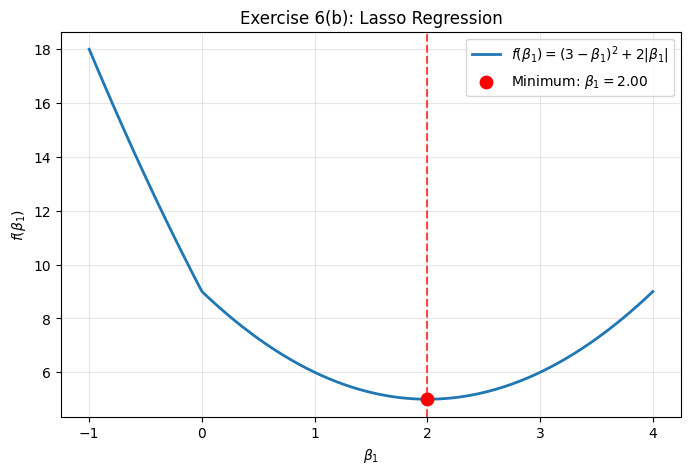

Optimal beta1 = 2.0000
Minimum objective value = 5.0000


In [28]:
# 4456Lasso Regression 目標函數
objective = (y1 - beta1)**2 + lam * np.abs(beta1)

# 公式 (6.15)：計算理論最佳解
beta1_hat = np.sign(y1) * max(abs(y1) - lam / 2, 0)

# 計算最小目標函數值
minimum = (y1 - beta1_hat)**2 + lam * abs(beta1_hat)

# 繪圖
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    beta1,
    objective,
    linewidth=2,
    label=r"$f(\beta_1)=(3-\beta_1)^2+2|\beta_1|$"
)

# 標示最小值
ax.scatter(
    beta1_hat,
    minimum,
    color="red",
    s=80,
    zorder=3,
    label=fr"Minimum: $\beta_1={beta1_hat:.2f}$"
)

# 畫出最佳解的垂直參考線
ax.axvline(
    beta1_hat,
    color="red",
    linestyle="--",
    alpha=0.7
)

ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel(r"$f(\beta_1)$")
ax.set_title("Exercise 6(b): Lasso Regression")

ax.legend()
ax.grid(alpha=0.3)

plt.show()

# 輸出結果
print(f"Optimal beta1 = {beta1_hat:.4f}")
print(f"Minimum objective value = {minimum:.4f}")

## Question 8

In this exercise, we will generate simulated data, and then will use this data to perform forward and backward stepwise selection.

**(a)** Create a random number generator and use its `normal()` method to generate a predictor $X$ of length $n = 100$, as well as a noise vector $\epsilon$ of length $n = 100$.

**(b)** Generate a response vector $Y$ of length $n = 100$ according to the model

$$
Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon,
$$

where $\beta_0$, $\beta_1$, $\beta_2$, and $\beta_3$ are constants of your choice.

**(c)** Use forward stepwise selection in order to select a model containing the predictors $X, X^2, \ldots, X^{10}$. What is the model obtained according to $C_p$? Report the coefficients of the model obtained.

**(d)** Repeat (c), using backwards stepwise selection. How does your answer compare to the results in (c)?

**(e)** Now fit a lasso model to the simulated data, again using $X, X^2, \ldots, X^{10}$ as predictors. Use cross-validation to select the optimal value of $\lambda$. Create plots of the cross-validation error as a function of $\lambda$. Report the resulting coefficient estimates, and discuss the results obtained.

**(f)** Now generate a response vector $Y$ according to the model

$$
Y = \beta_0 + \beta_7 X^7 + \epsilon,
$$

and perform forward stepwise selection and the lasso. Discuss the results obtained.

### (a) 解答

設定樣本數 $n=100$，建立亂數產生器，並使用其 `normal()` 方法，分別產生預測變數 $X$ 與隨機誤差 $\epsilon$。

題目要用 `normal()` 做生成，所以

$$
X_i\overset{\mathrm{iid}}{\sim}N(0,1),
\qquad
\epsilon_i\overset{\mathrm{iid}}{\sim}N(0,1),
\qquad i=1,\ldots,100,
$$

且預測變數與誤差彼此獨立。

如此得到兩個長度皆為 100 的向量：

$$
X=(X_1,\ldots,X_{100}),
\qquad
\epsilon=(\epsilon_1,\ldots,\epsilon_{100}).
$$

其中，$X$ 將作為後續建立多項式解釋項的來源；$\epsilon$ 則代表資料中的隨機波動。

亂數種子設定為 20261028。

In [29]:
n = 100
rng = np.random.default_rng(20261028)

# 產生預測變數 X
x = rng.normal(size=n)

# 產生隨機誤差 epsilon
epsilon = rng.normal(size=n)

print(x.shape)
print(epsilon.shape)

(100,)
(100,)


### (b) 解答

將模型

$$
Y_i
=
\beta_0+\beta_1X_i+\beta_2X_i^2+\beta_3X_i^3+\epsilon_i,
\qquad i=1,\ldots,100,
$$

代入自己假設的係數

$$
\beta_0=1,\qquad
\beta_1=2,\qquad
\beta_2=-3,\qquad
\beta_3=1.
$$

代入後，資料生成模型為

$$
\boxed{
Y_i=1+2X_i-3X_i^2+X_i^3+\epsilon_i
}.
$$

使用 (a) 產生的預測變數與誤差，逐筆計算對應的 $Y_i$，即可得到長度為 100 的反應向量 $Y$。

由於誤差與 $X$ 獨立且平均數為 0，因此

$$
E(Y\mid X=x)=1+2x-3x^2+x^3.
$$

這表示 $Y$ 的條件平均數是一條三次曲線，而隨機誤差使實際觀測值在曲線周圍波動。

In [30]:
beta0 = 1
beta1 = 2
beta2 = -3
beta3 = 1

y = (
    beta0
    + beta1 * x
    + beta2 * x**2
    + beta3 * x**3
    + epsilon
)

### (c) 解答

將 $X,X^2,\ldots,X^{10}$ 作為十個候選解釋項，並使用 forward stepwise 選擇：

1. 從只包含截距的模型開始。
2. 每一步分別嘗試加入所有尚未選入的項，選擇使殘差平方和 RSS 最小的那一項。
3. 保留已選入的項，持續進行直到十個項全部加入。
4. 比較每一步模型的 $C_p$，選擇 $C_p$ 最小的模型。

因此，加入順序由資料決定，並不是固定依照 $X,X^2,X^3,\ldots$ 的次序加入。

依課本公式 (6.2)

$$
C_p=\frac{\operatorname{RSS}+2k\hat{\sigma}^2}{n},
$$

其中 $n=100$，$k$ 為不包含截距的解釋項數目。

誤差變異數使用包含全部十個解釋項的完整模型估計，並在比較所有候選模型時使用同一個估計值：

$$
\hat{\sigma}^2
=
\frac{\operatorname{RSS}_{\mathrm{full}}}{n-10-1}
=
\frac{89.993273}{89}
\approx 1.011160.
$$

前進逐步選擇的結果如下：

| 解釋項數目 $k$ | 本步新增項 | $C_p$ |
|---:|---|---:|
| 0 | 僅截距 | 53.794207 |
| 1 | $X^3$ | 17.472139 |
| 2 | $X^2$ | 2.018139 |
| 3 | $X$ | 1.049265 |
| 4 | $X^4$ | 1.034043 |
| 5 | $X^5$ | 1.036550 |
| 6 | $X^7$ | 1.054724 |
| 7 | $X^{10}$ | 1.070407 |
| 8 | $X^6$ | 1.087099 |
| 9 | $X^8$ | 1.091187 |
| 10 | $X^9$ | 1.102165 |

最小的 $C_p$ 約為 1.034043，發生在 $k = 4$ 時，因此選取

$$
\boxed{X,\ X^2,\ X^3,\ X^4}.
$$

其係數估計所得到的預測模型為

$$
\boxed{
\hat{Y}
=
0.957324
+1.863469X
-2.631037X^2
+0.986790X^3
-0.081856X^4
}.
$$

相較於真實生成模型，前進逐步選擇保留了必要的 $X$、$X^2$ 與 $X^3$，但也額外選入了 $X^4$。

所以 $C_p$ 最小的模型不一定就是真實生成模型。本次加入四次項後，$C_p$ 由三次模型的 1.049265 降至 1.034043，僅下降約 0.015222，表示增加四次項在此準則下帶來的改善有限。

雖然選出的模型額外包含 $X^4$，但仍保留了真實模型中的 $X$、$X^2$ 與 $X^3$，因此在解釋項的組成上與真實模型相近。

In [31]:
import statsmodels.api as sm
import pandas as pd

n = len(y)

# 建立十個候選解釋項
X_poly = pd.DataFrame({
    f"X^{power}": x**power
    for power in range(1, 11)
})


# 根據指定的解釋項，以最小平方法配適含截距的模型
def fit_model(features):
    design = sm.add_constant(
        X_poly.loc[:, features],
        has_constant="add",
    )
    return sm.OLS(y, design).fit()


# 用完整模型估計誤差變異數
full_fit = fit_model(list(X_poly.columns))
sigma2_hat = full_fit.mse_resid

# 從只包含截距的模型開始
selected = []
remaining = list(X_poly.columns)

null_fit = fit_model([])

forward_models = [null_fit]
forward_rows = [{
    "n_features": 0,
    "added": "-",
    "features": [],
    "RSS": null_fit.ssr,
    "Cp": null_fit.ssr / n,
}]

# 每一步從尚未加入的項中，選擇使 RSS 最小的項
for step in range(1, X_poly.shape[1] + 1):
    candidates = [
        (feature, fit_model(selected + [feature]))
        for feature in remaining
    ]

    best_feature, best_fit = min(
        candidates,
        key=lambda item: item[1].ssr,
    )

    selected.append(best_feature)
    remaining.remove(best_feature)

    # 課本定義：k 不包含截距
    cp = (
        best_fit.ssr
        + 2 * step * sigma2_hat
    ) / n

    forward_models.append(best_fit)

    forward_rows.append({
        "n_features": step,
        "added": best_feature,
        "features": selected.copy(),
        "RSS": best_fit.ssr,
        "Cp": cp,
    })

forward_results = pd.DataFrame(forward_rows)

# 使用完整精度的 Cp 選出最佳模型
best_index = forward_results["Cp"].idxmin()
best_features = forward_results.loc[best_index, "features"]
best_forward_model = forward_models[best_index]

# 最後模型選擇參數
ordered_features = [
    name for name in X_poly.columns
    if name in best_features
]
ordered_terms = ["const"] + ordered_features

print(f"完整模型估計的誤差變異數：{sigma2_hat:.6f}")

print("\n前進逐步選擇結果：")
print(
    forward_results[
        ["n_features", "added", "RSS", "Cp"]
    ].to_string(
        index=False,
        formatters={
            "RSS": "{:.6f}".format,
            "Cp": "{:.6f}".format,
        },
    )
)

print("\n最終選取的解釋項：")
print(ordered_features)

print("\n最終模型的係數估計：")
print(
    best_forward_model.params.loc[ordered_terms].to_string(
        float_format=lambda value: f"{value:.6f}"
    )
)

完整模型估計的誤差變異數：1.011160

前進逐步選擇結果：
 n_features added         RSS        Cp
          0     - 5379.420714 53.794207
          1   X^3 1745.191535 17.472139
          2   X^2  197.769239  2.018139
          3   X^1   98.859512  1.049265
          4   X^4   95.314993  1.034043
          5   X^5   93.543419  1.036550
          6   X^7   93.338521  1.054724
          7  X^10   92.884482  1.070407
          8   X^6   92.531296  1.087099
          9   X^8   90.917774  1.091187
         10   X^9   89.993273  1.102165

最終選取的解釋項：
['X^1', 'X^2', 'X^3', 'X^4']

最終模型的係數估計：
const    0.957324
X^1      1.863469
X^2     -2.631037
X^3      0.986790
X^4     -0.081856


### (d) 解答

backward stepwise 從包含 $X,X^2,\ldots,X^{10}$ 的完整模型開始。

每一步分別嘗試刪除目前模型中的一個解釋項，保留刪除後 RSS 最小的模型，再繼續刪除，直到只剩截距。最後比較整條選擇路徑上的 $C_p$，選出最小者。

沿用 (c) 的計算方式：

$$
C_p=\frac{\operatorname{RSS}+2k\hat{\sigma}^2}{n},
$$

其中 $k$ 不包含截距，且所有模型都使用相同的完整模型誤差變異數估計：

$$
\hat{\sigma}^2\approx 1.011160.
$$

後退逐步選擇的結果如下：

| 剩餘解釋項數目 $k$ | 本步刪除項 | $C_p$ |
|---:|---|---:|
| 10 | 尚未刪除 | 1.102165 |
| 9 | $X^9$ | 1.091187 |
| 8 | $X^7$ | 1.073185 |
| 7 | $X^5$ | 1.059481 |
| 6 | $X^4$ | 1.062274 |
| 5 | $X^{10}$ | 1.045356 |
| 4 | $X^8$ | 1.040513 |
| 3 | $X^6$ | 1.049265 |
| 2 | $X$ | 2.018139 |
| 1 | $X^2$ | 17.472139 |
| 0 | $X^3$ | 53.794207 |

最小的 $C_p$ 約為 1.040513，對應的解釋項為

$$
\boxed{X,\ X^2,\ X^3,\ X^6}.
$$

估計出的預測模型為

$$
\boxed{
\hat{Y}
=
1.003057
+1.874184X
-2.801034X^2
+0.980179X^3
-0.009243X^6
}.
$$

與 (c) 的結果比較：

| 方法 | 選取的解釋項 | 最小 $C_p$ |
|---|---|---:|
| forward stepwise | $X,X^2,X^3,X^4$ | 1.034043 |
| backward stepwise | $X,X^2,X^3,X^6$ | 1.040513 |

兩種方法都選了四個解釋項，也都保留真實生成模型中的 $X$、$X^2$ 與 $X^3$，但額外選入的項不同：forward stepwise 加入 $X^4$，backward stepwise 則保留 $X^6$。

造成差異的原因是兩種方法的搜尋路徑不同。前進法先選入 $X^3$、$X^2$ 與 $X$，接著在其餘候選項中選入 $X^4$；backward stepwise則從完整模型開始，在仍包含其他高次項時，便已刪除 $X^4$，後續不會再將它加回。因此，backward stepwise 後來已無法考慮前進法最後選出的那個組合。

本次 forward stepwise 的 $C_p$ 比 backward stepwise 低約 0.006470。由於兩者的解釋項數目相同，複雜度懲罰相同，這個差異來自前進模型較低的 RSS。

因此，依本次的 $C_p$ 準則，forward stepwise 選出的模型略優，但兩者數值相近；這不代表 forward stepwise 在其他資料中一定較好。逐步選擇只搜尋部分模型組合，搜尋方向不同便可能產生不同結果。

In [32]:
backward_selected = list(X_poly.columns)

backward_models = [full_fit]
backward_rows = [{
    "n_features": len(backward_selected),
    "removed": "-",
    "features": backward_selected.copy(),
    "RSS": full_fit.ssr,
    "Cp": (
        full_fit.ssr
        + 2 * len(backward_selected) * sigma2_hat
    ) / n,
}]

# 持續刪除，直到只剩截距
while backward_selected:
    candidates = []

    # 分別嘗試刪除目前模型中的每一個項
    for feature in backward_selected:
        trial_features = [
            name for name in backward_selected
            if name != feature
        ]

        trial_fit = fit_model(trial_features)
        candidates.append((feature, trial_fit))

    # 保留刪除後 RSS 最小的模型
    removed_feature, best_fit = min(
        candidates,
        key=lambda item: item[1].ssr,
    )

    backward_selected.remove(removed_feature)
    k = len(backward_selected)

    backward_models.append(best_fit)
    backward_rows.append({
        "n_features": k,
        "removed": removed_feature,
        "features": backward_selected.copy(),
        "RSS": best_fit.ssr,
        "Cp": (
            best_fit.ssr
            + 2 * k * sigma2_hat
        ) / n,
    })

backward_results = pd.DataFrame(backward_rows)

# 走完整條選擇路徑後，再選出 Cp 最小的模型
best_backward_index = backward_results["Cp"].idxmin()

best_backward_features = backward_results.loc[
    best_backward_index, "features"
]
best_backward_model = backward_models[best_backward_index]

print("後退逐步選擇結果：")
print(
    backward_results[
        ["n_features", "removed", "RSS", "Cp"]
    ].to_string(
        index=False,
        formatters={
            "RSS": "{:.6f}".format,
            "Cp": "{:.6f}".format,
        },
    )
)

print("\n最終選取的解釋項：")
print(best_backward_features)

print("\n最終模型的係數估計：")
print(
    best_backward_model.params.to_string(
        float_format=lambda value: f"{value:.6f}"
    )
)

# 比較前進與後退選擇的最佳模型
forward_best_row = forward_results.loc[
    forward_results["Cp"].idxmin()
]
backward_best_row = backward_results.loc[best_backward_index]

comparison = pd.DataFrame([
    {
        "method": "Forward",
        "features": ", ".join(
            name for name in X_poly.columns
            if name in forward_best_row["features"]
        ),
        "Cp": forward_best_row["Cp"],
    },
    {
        "method": "Backward",
        "features": ", ".join(best_backward_features),
        "Cp": backward_best_row["Cp"],
    },
])

print("\n前進與後退逐步選擇比較：")
print(
    comparison.to_string(
        index=False,
        formatters={"Cp": "{:.6f}".format},
    )
)

後退逐步選擇結果：
 n_features removed         RSS        Cp
         10       -   89.993273  1.102165
          9     X^9   90.917774  1.091187
          8     X^7   91.139911  1.073185
          7     X^5   91.791863  1.059481
          6     X^4   94.093516  1.062274
          5    X^10   94.423969  1.045356
          4     X^8   95.962041  1.040513
          3     X^6   98.859512  1.049265
          2     X^1  197.769239  2.018139
          1     X^2 1745.191535 17.472139
          0     X^3 5379.420714 53.794207

最終選取的解釋項：
['X^1', 'X^2', 'X^3', 'X^6']

最終模型的係數估計：
const    1.003057
X^1      1.874184
X^2     -2.801034
X^3      0.980179
X^6     -0.009243

前進與後退逐步選擇比較：
  method           features       Cp
 Forward X^1, X^2, X^3, X^4 1.034043
Backward X^1, X^2, X^3, X^6 1.040513


### (e) 解釋

以 $X,X^2,\ldots,X^{10}$ 作為候選解釋項，建立 lasso 模型。

由於不同次方項的尺度差異很大，因此先將各項標準化，再配適模型。標準化與模型配適放在同一個 Pipeline 中，確保每一折只使用該折訓練資料計算平均數及標準差。

令 $Z_{ij}$ 表示標準化後的第 $j$ 次方項，lasso 的目標函數為

$$
\min_{a,\theta_1,\ldots,\theta_{10}}
\left\{
\frac{1}{2m}
\sum_{i=1}^{m}
\left(
Y_i-a-\sum_{j=1}^{10}\theta_jZ_{ij}
\right)^2
+
\lambda\sum_{j=1}^{10}|\theta_j|
\right\},
$$

使用十折交叉驗證，將資料隨機分成十組，分組種子設定為 `20261028`。在 $10^{-3}$ 至 $10^1$ 之間建立 100 個對數等距的候選 $\lambda$，選擇平均驗證均方誤差最小者。

本次候選網格中選出的參數為

$$
\boxed{\lambda_{\min}\approx 0.031257},
$$

對應的十折平均驗證誤差為

$$
\boxed{\operatorname{CV\ MSE}\approx 1.074172}.
$$

選定參數後，使用全部 100 筆資料重新配適模型，並將係數轉回原始的多項式尺度，結果如下：

| 模型項 | 係數估計值 |
|---|---:|
| 截距 | 0.935137 |
| $X$ | 1.839341 |
| $X^2$ | -2.609478 |
| $X^3$ | 0.985272 |
| $X^4$ | -0.082163 |
| $X^5,\ldots,X^{10}$ | 各項皆為 0 |

因此，預測模型為

$$
\boxed{
\hat{Y}
=
0.935137
+1.839341X
-2.609478X^2
+0.985272X^3
-0.082163X^4
}.
$$

從交叉驗證曲線可以看到，當 $\lambda=0.001$ 時，平均驗證誤差約為 1.412232；增加懲罰至 $\lambda\approx0.031257$ 後，誤差下降至 1.074172，代表適度增加逞罰係數會改善表現。

但當 $\lambda$ 過大時，係數受到過度壓縮，模型難以描述資料的主要關係。例如 $\lambda=10$ 時，驗證誤差上升至約 54.135860。最低點附近的曲線則較平坦，表示鄰近的懲罰參數具有相近的驗證表現。

本次 lasso 保留了 $X,X^2,X^3,X^4$，與前進逐步選擇保留的項相同。不過，前進法選定變數後使用最小平方法估計係數，lasso 則在估計時加入懲罰，因此兩者的係數數值不同。

相較於真實生成模型 $Y=1+2X-3X^2+X^3+\epsilon$，lasso 保留了全部必要項，並將六個高次項的係數壓成零，但仍額外保留了 $X^4$。這表示 lasso 能產生較精簡的模型，但本次仍未完全恢復真實的三次模型。

最佳 lambda：0.03125716
最小十折 CV MSE：1.074172
非零解釋項數目（不含截距）：4
保留的解釋項： ['X^1', 'X^2', 'X^3', 'X^4']

原始尺度的係數估計：
 term     coefficient
const  9.35137487e-01
  X^1  1.83934068e+00
  X^2 -2.60947820e+00
  X^3  9.85272359e-01
  X^4 -8.21633745e-02
  X^5  0.00000000e+00
  X^6  0.00000000e+00
  X^7  0.00000000e+00
  X^8  0.00000000e+00
  X^9  0.00000000e+00
 X^10  0.00000000e+00


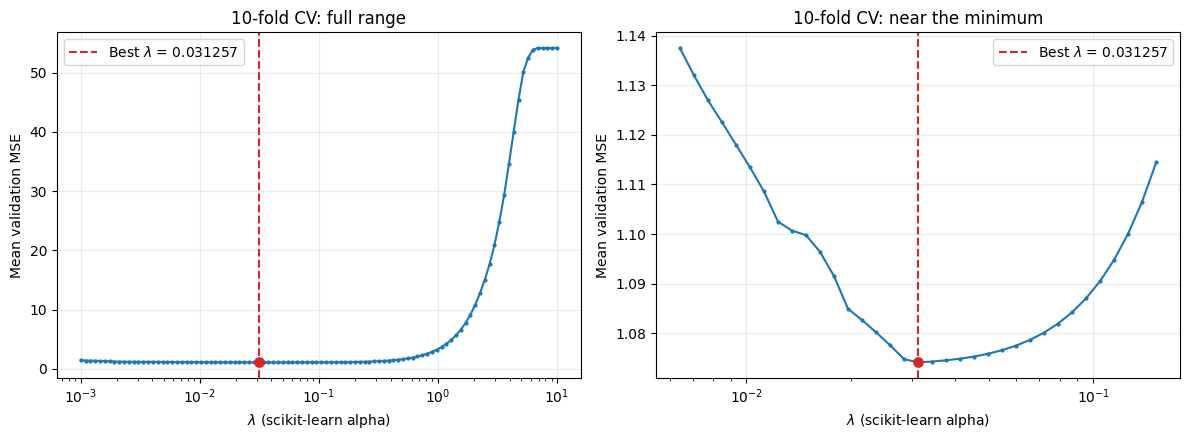

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, GridSearchCV

# 1. 建立十個候選解釋項
X_lasso = pd.DataFrame({
    f"X^{power}": x**power
    for power in range(1, 11)
})

# 本文 lambda 對應 sklearn 的 alpha
lambda_grid = np.logspace(-3, 1, 100)

# 固定交叉驗證的分組，讓結果可以重現
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=20261028,
)

# 標準化放在 Pipeline 中，於每一折的訓練資料內進行
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        max_iter=200000,
        tol=1e-8,
    )),
])

# 2. 交叉驗證選擇 lambda
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": lambda_grid},
    scoring="neg_mean_squared_error",
    cv=cv,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

lasso_search.fit(X_lasso, y)

best_lambda = lasso_search.best_params_["lasso__alpha"]
best_cv_mse = -lasso_search.best_score_

# 整理各 lambda 的平均驗證誤差
cv_table = pd.DataFrame({
    "lambda": np.asarray(
        lasso_search.cv_results_["param_lasso__alpha"],
        dtype=float,
    ),
    "cv_mse": -lasso_search.cv_results_["mean_test_score"],
}).sort_values("lambda").reset_index(drop=True)

# 3. 取得使用全部資料重新配適的最佳模型
best_lasso_pipeline = lasso_search.best_estimator_

scaler = best_lasso_pipeline.named_steps["scaler"]
lasso = best_lasso_pipeline.named_steps["lasso"]

# 將係數轉回原始多項式尺度
raw_coefs = lasso.coef_ / scaler.scale_

raw_intercept = (
    lasso.intercept_
    - np.dot(scaler.mean_, raw_coefs)
)

# 將負零整理成一般的零，不改動非零係數
raw_coefs[raw_coefs == 0] = 0.0

coefficient_table = pd.DataFrame({
    "term": ["const"] + list(X_lasso.columns),
    "coefficient": np.r_[raw_intercept, raw_coefs],
})

selected_features = X_lasso.columns[
    lasso.coef_ != 0
].tolist()

print(f"最佳 lambda：{best_lambda:.8f}")
print(f"最小十折 CV MSE：{best_cv_mse:.6f}")
print(f"非零解釋項數目（不含截距）：{len(selected_features)}")
print("保留的解釋項：", selected_features)

print("\n原始尺度的係數估計：")
print(
    coefficient_table.to_string(
        index=False,
        formatters={
            "coefficient": "{:.8e}".format,
        },
    )
)

# 4. 繪製完整曲線與最低點附近的放大圖
zoom = cv_table.loc[
    (cv_table["lambda"] >= best_lambda / 5)
    & (cv_table["lambda"] <= best_lambda * 5)
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, table, title in zip(
    axes,
    [cv_table, zoom],
    [
        "10-fold CV: full range",
        "10-fold CV: near the minimum",
    ],
):
    ax.semilogx(
        table["lambda"],
        table["cv_mse"],
        color="tab:blue",
        marker=".",
        markersize=4,
    )

    ax.axvline(
        best_lambda,
        color="tab:red",
        linestyle="--",
        label=fr"Best $\lambda$ = {best_lambda:.6f}",
    )

    ax.scatter(
        best_lambda,
        best_cv_mse,
        color="tab:red",
        s=45,
        zorder=3,
    )

    ax.set(
        xlabel=r"$\lambda$ (scikit-learn alpha)",
        ylabel="Mean validation MSE",
        title=title,
    )

    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

### (f) 解答

設定 $\beta_0=1$、$\beta_7=1$，使用原本的 $X$ 與誤差向量，產生新的反應變數：

$$
Y_i=1+X_i^7+\epsilon_i.
$$

因此，真實模型只需要截距與 $X^7$，其餘候選項的真實係數皆為 0。

#### 使用 forward stepwise

以 $X,X^2,\ldots,X^{10}$ 為候選項，使用與 (c) 相同的 forward stepwise 及 $C_p$ 計算方式。

方法首先選入 $X^7$，接著加入 $X^{10}$。在完整選擇路徑中，最小的 $C_p$ 為

$$
\boxed{C_p\approx1.027126},
$$

對應的預測模型為

$$
\boxed{
\hat{Y}_{\mathrm{forward}}
=
1.132285
+0.998049X^7
-1.548271\times10^{-4}X^{10}
}.
$$

方法成功找出主要的真實項 $X^7$，且其係數估計值 0.998049 接近真實值 1，但也額外保留了 $X^{10}$。

只有 $X^7$ 的模型，其 $C_p$ 為 1.030333；加入 $X^{10}$ 後降至 1.027126，僅改善約 0.003207。因此，兩個模型在此準則下的差距很小，不能把額外選入第十次項解讀為真實關係需要它。

#### Lasso

同樣以十個多項式項為候選變數，在每個訓練折內標準化，再用十折交叉驗證選擇懲罰參數。

交叉驗證的分組種子設定為 `20261028`，候選參數為 $10^{-3}$ 至 $10^1$ 之間的 100 個對數等距數值。本文的 $\lambda$ 仍對應 sklearn 的 `alpha`。

本次選出的參數與平均驗證誤差為

$$
\boxed{\lambda_{\min}\approx0.065793},
$$

$$
\boxed{\operatorname{CV\ MSE}\approx1.107194}.
$$

使用選定參數對全部資料重新配適，並將係數轉回原始多項式尺度後，得到

$$
\begin{aligned}
\hat{Y}_{\mathrm{lasso}}
={}&1.117600
+0.993058X^7\\
&-3.741237\times10^{-4}X^8\\
&+9.083558\times10^{-4}X^9\\
&-4.425022\times10^{-6}X^{10}.
\end{aligned}
$$

其中，$X$ 至 $X^6$ 的係數皆被壓成 0，保留的項為

$$
\boxed{X^7,\ X^8,\ X^9,\ X^{10}}.
$$

#### 結果

| 方法 | 保留的非截距項 | 是否完全恢復真實模型 |
|---|---|---|
| 前進逐步選擇 | $X^7,X^{10}$ | 否，多選了 $X^{10}$ |
| Lasso | $X^7,X^8,X^9,X^{10}$ | 否，多選了三個高次項 |

兩種方法都選出真實的 $X^7$，但前進法額外保留 $X^{10}$，lasso 則額外保留 $X^8,X^9,X^{10}$，因此都未完全恢復真實模型。

差異在於：$C_p$ 直接懲罰模型的項數；lasso 懲罰的是標準化係數的絕對值總和，因此多保留幾項小係數，不一定受到較大的懲罰。加上高次項彼此相關，額外項可能配合主要項擬合樣本中的隨機波動，所以 lasso 不一定選出較少的項。

此外，交叉驗證選擇的是預測誤差較低的懲罰強度，並不保證找回真實模型。高次項的影響也應看 $\hat{\beta}_jX^j$；即使係數很小，乘上較大的 $X^j$ 後，仍可能明顯改變預測。

In [34]:
beta0_f = 1
beta7_f = 1

y_f = beta0_f + beta7_f * x**7 + epsilon
n_f = len(y_f)

X_poly_f = pd.DataFrame({
    f"X^{power}": x**power
    for power in range(1, 11)
})


# 注意：這個函數使用本小題的新反應變數 y_f
def fit_model_f(features):
    design = sm.add_constant(
        X_poly_f.loc[:, features],
        has_constant="add",
    )
    return sm.OLS(y_f, design).fit()


# 2. 前進逐步選擇
full_fit_f = fit_model_f(list(X_poly_f.columns))
sigma2_hat_f = full_fit_f.mse_resid

selected_f = []
remaining_f = list(X_poly_f.columns)

null_fit_f = fit_model_f([])

forward_models_f = [null_fit_f]
forward_rows_f = [{
    "n_features": 0,
    "added": "-",
    "features": [],
    "RSS": null_fit_f.ssr,
    "Cp": null_fit_f.ssr / n_f,
}]

while remaining_f:
    candidates = [
        (feature, fit_model_f(selected_f + [feature]))
        for feature in remaining_f
    ]

    added_feature, best_fit = min(
        candidates,
        key=lambda item: item[1].ssr,
    )

    selected_f.append(added_feature)
    remaining_f.remove(added_feature)

    k = len(selected_f)

    forward_models_f.append(best_fit)
    forward_rows_f.append({
        "n_features": k,
        "added": added_feature,
        "features": selected_f.copy(),
        "RSS": best_fit.ssr,
        "Cp": (
            best_fit.ssr + 2 * k * sigma2_hat_f
        ) / n_f,
    })

forward_results_f = pd.DataFrame(forward_rows_f)

best_forward_index_f = forward_results_f["Cp"].idxmin()
best_forward_model_f = forward_models_f[best_forward_index_f]

best_forward_features_f = forward_results_f.loc[
    best_forward_index_f, "features"
]
best_cp_f = forward_results_f.loc[
    best_forward_index_f, "Cp"
]

# 3. Lasso：十折交叉驗證選擇 lambda
lambda_grid_f = np.logspace(-3, 1, 100)

cv_f = KFold(
    n_splits=10,
    shuffle=True,
    random_state=20261028,
)

lasso_pipeline_f = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        max_iter=1_000_000,
        tol=1e-12,
    )),
])

lasso_search_f = GridSearchCV(
    estimator=lasso_pipeline_f,
    param_grid={"lasso__alpha": lambda_grid_f},
    scoring="neg_mean_squared_error",
    cv=cv_f,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

lasso_search_f.fit(X_poly_f, y_f)

best_lambda_f = lasso_search_f.best_params_["lasso__alpha"]
best_cv_mse_f = -lasso_search_f.best_score_

scaler_f = lasso_search_f.best_estimator_.named_steps["scaler"]
lasso_f = lasso_search_f.best_estimator_.named_steps["lasso"]

# 將 lasso 係數轉回原始多項式尺度
raw_coefs_f = lasso_f.coef_ / scaler_f.scale_

raw_intercept_f = (
    lasso_f.intercept_
    - np.dot(scaler_f.mean_, raw_coefs_f)
)

raw_coefs_f[raw_coefs_f == 0] = 0.0

selected_lasso_f = X_poly_f.columns[
    lasso_f.coef_ != 0
].tolist()

# 4. 整理兩種方法的係數
all_terms_f = ["const"] + list(X_poly_f.columns)

coefficient_comparison_f = pd.DataFrame({
    "Forward": best_forward_model_f.params.reindex(
        all_terms_f,
        fill_value=0.0,
    ),
    "Lasso": pd.Series(
        np.r_[raw_intercept_f, raw_coefs_f],
        index=all_terms_f,
    ),
})

print("前進逐步選擇結果：")
print(
    forward_results_f[
        ["n_features", "added", "RSS", "Cp"]
    ].to_string(
        index=False,
        formatters={
            "RSS": "{:.6f}".format,
            "Cp": "{:.6f}".format,
        },
    )
)

print("\n前進法保留的項：", best_forward_features_f)
print(f"前進法最小 Cp：{best_cp_f:.6f}")

print("\nLasso 保留的項：", selected_lasso_f)
print(f"Lasso 最佳 lambda：{best_lambda_f:.8f}")
print(f"Lasso 最小十折 CV MSE：{best_cv_mse_f:.6f}")

print("\n原始尺度的係數比較（未選入的項以 0 表示）：")
print(
    coefficient_comparison_f.to_string(
        float_format=lambda value: f"{value:.8e}"
    )
)

前進逐步選擇結果：
 n_features added            RSS           Cp
          0     - 1089503.321325 10895.033213
          1   X^7     101.010949     1.030333
          2  X^10      98.667959     1.027126
          3   X^2      97.322705     1.033897
          4   X^4      95.745765     1.038350
          5   X^1      94.648846     1.047604
          6   X^3      93.835911     1.059698
          7   X^5      92.884482     1.070407
          8   X^6      92.531296     1.087099
          9   X^8      90.917774     1.091187
         10   X^9      89.993273     1.102165

前進法保留的項： ['X^7', 'X^10']
前進法最小 Cp：1.027126

Lasso 保留的項： ['X^7', 'X^8', 'X^9', 'X^10']
Lasso 最佳 lambda：0.06579332
Lasso 最小十折 CV MSE：1.107194

原始尺度的係數比較（未選入的項以 0 表示）：
              Forward           Lasso
const  1.13228509e+00  1.11759986e+00
X^1    0.00000000e+00  0.00000000e+00
X^2    0.00000000e+00  0.00000000e+00
X^3    0.00000000e+00  0.00000000e+00
X^4    0.00000000e+00  0.00000000e+00
X^5    0.00000000e+00  0.00000000e+00
X^6   

## Question 9

In this exercise, we will predict the number of applications received using the other variables in the `College` data set.

**(a)** Split the data set into a training set and a test set.

**(b)** Fit a linear model using least squares on the training set, and report the test error obtained.

**(c)** Fit a ridge regression model on the training set, with $\lambda$ chosen by cross-validation. Report the test error obtained.

**(d)** Fit a lasso model on the training set, with $\lambda$ chosen by cross-validation. Report the test error obtained, along with the number of non-zero coefficient estimates.

**(e)** Fit a PCR model on the training set, with $M$ chosen by cross-validation. Report the test error obtained, along with the value of $M$ selected by cross-validation.

**(f)** Fit a PLS model on the training set, with $M$ chosen by cross-validation. Report the test error obtained, along with the value of $M$ selected by cross-validation.

**(g)** Comment on the results obtained. How accurately can we predict the number of college applications received? Is there much difference among the test errors resulting from these five approaches?

### (a) 解答

以 `Apps` 為反應變數，其餘 17 個變數作為預測變數。

其中，`Private` 為類別變數，因此將其轉換成虛擬變數：

$$
\mathrm{Private\_Yes}
=
\begin{cases}
1, & \text{私立大學},\\
0, & \text{公立大學}.
\end{cases}
$$

資料共有 777 所學校，且沒有缺失值，預測變數數目為 17。設定亂數種子為 `20261028`，隨機將約 70% 的資料分配至訓練集，其餘約 30% 分配至測試集，得到：

- 訓練集：543 所學校。
- 測試集：234 所學校。


In [35]:
from ISLP import load_data
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

College = load_data("College")

# 反應變數
y_college = College["Apps"]

# Private 轉成虛擬變數，以公立大學為參考類別
X_college = pd.get_dummies(
    College.drop(columns="Apps"),
    columns=["Private"],
    drop_first=True,
    dtype=int,
)

X_train, X_test, y_train, y_test = train_test_split(
    X_college,
    y_college,
    test_size=0.30,
    random_state=20261028,
)

print(f"資料總筆數：{len(College)}")
print(f"缺失值總數：{College.isna().sum().sum()}")
print(f"預測變數數目：{X_college.shape[1]}")
print(f"訓練集筆數：{len(X_train)}")
print(f"測試集筆數：{len(X_test)}")

print("\n訓練集與測試集的申請數分布：")
print(
    pd.DataFrame({
        "Train": y_train.describe(),
        "Test": y_test.describe(),
    }).round(2)
)

資料總筆數：777
缺失值總數：0
預測變數數目：17
訓練集筆數：543
測試集筆數：234

訓練集與測試集的申請數分布：
          Train      Test
count    543.00    234.00
mean    2994.67   3017.80
std     3666.20   4314.93
min       81.00    141.00
25%      736.00    821.75
50%     1464.00   1784.50
75%     3710.00   3579.75
max    21804.00  48094.00


### (b) 解答

使用訓練集配適包含全部 17 個預測變數與截距的線性迴歸模型：

$$
\mathrm{Apps}_i
=
\beta_0+\sum_{j=1}^{17}\beta_jX_{ij}+\epsilon_i.
$$

係數以最小平方法估計，再將模型套用至測試集。測試均方誤差定義為

$$
\operatorname{MSE}_{\mathrm{test}}
=
\frac{1}{234}
\sum_{i\in\mathrm{test}}
\left(y_i-\hat{y}_i\right)^2.
$$

本次結果為：

| 評估指標 | 最小平方法 |
|---|---:|
| 測試 MSE | 1,861,234.76 |
| 測試 RMSE | 1,364.27 |
| 測試 MAE | 698.32 |
| 測試 $R^2$ | 0.8996 |

因此，本題要求的測試誤差為

$$
\boxed{
\operatorname{MSE}_{\mathrm{test}}
\approx1,861,234.76
}.
$$

RMSE 約為 1,364 份申請；MAE 則表示，每所學校的預測申請數與實際申請數，平均相差約 698 份。兩者不同，是因為 RMSE 對少數較大的預測誤差給予較高權重。

作為比較，若對所有測試學校都預測訓練集的平均申請數，其測試 MSE 約為 18,539,618.55。線性迴歸將此誤差降低約 90%，顯示這些預測變數提供了相當多的預測資訊。

不過，測試 $R^2=0.8996$ 並不代表每所學校的預測都很準確，測試集中申請數最多的學校共有 48,094 份申請，但模型僅預測約 34,673.77 份，低估約 13,420.23 份。這一筆資料便占全部測試殘差平方和的約 41.35%。

此外，訓練集最大的申請數只有 21,804。這表示測試集包含一個訓練集中未出現的極高申請數案例，且整體 MSE 明顯受到這筆大誤差影響。因此，模型整體表現雖然不錯，對極高申請數學校的預測仍有明顯不足。

In [36]:
ols_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

ols_model.fit(X_train, y_train)
ols_pred = ols_model.predict(X_test)


# 評估方式
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Test MSE": mse,
        "Test RMSE": np.sqrt(mse),
        "Test MAE": mean_absolute_error(y_true, y_pred),
        "Test R2": r2_score(y_true, y_pred),
    }


# 基準模型：所有測試資料皆預測訓練集平均數
baseline_pred = np.full(
    len(y_test),
    y_train.mean(),
)

ols_metrics = regression_metrics(y_test, ols_pred)
baseline_metrics = regression_metrics(y_test, baseline_pred)

print("測試集表現：")
print(
    pd.DataFrame({
        "Baseline": baseline_metrics,
        "OLS": ols_metrics,
    }).T.to_string(float_format=lambda value: f"{value:,.4f}")
)

# 檢查個別學校對整體平方誤差的貢獻
ols_diagnostics = pd.DataFrame({
    "Actual": y_test,
    "Predicted": ols_pred,
})

ols_diagnostics["Residual"] = (
    ols_diagnostics["Actual"]
    - ols_diagnostics["Predicted"]
)

ols_diagnostics["Squared error"] = (
    ols_diagnostics["Residual"] ** 2
)

ols_diagnostics["SSE share"] = (
    ols_diagnostics["Squared error"]
    / ols_diagnostics["Squared error"].sum()
)

print("\n平方誤差最大的五筆資料：")
print(
    ols_diagnostics.nlargest(5, "Squared error").to_string(
        formatters={
            "Predicted": "{:,.2f}".format,
            "Residual": "{:,.2f}".format,
            "Squared error": "{:,.2f}".format,
            "SSE share": "{:.2%}".format,
        }
    )
)

測試集表現：
                Test MSE  Test RMSE   Test MAE  Test R2
Baseline 18,539,618.5535 4,305.7657 2,347.2842  -0.0000
OLS       1,861,234.7554 1,364.2708   698.3206   0.8996

平方誤差最大的五筆資料：
     Actual Predicted  Residual  Squared error SSE share
483   48094 34,673.77 13,420.23 180,102,632.91    41.35%
250   13865  7,344.54  6,520.46  42,516,418.98     9.76%
174   13789  8,699.65  5,089.35  25,901,510.13     5.95%
605   19873 14,889.82  4,983.18  24,832,090.58     5.70%
445   19315 14,626.76  4,688.24  21,979,601.00     5.05%


### (c) 解答

Ridge regression 在最小平方法的目標函數中加入係數平方的懲罰：

$$
\sum_{i\in\mathrm{train}}
\left(
y_i-\beta_0-\sum_{j=1}^{17}\theta_jz_{ij}
\right)^2
+
\lambda\sum_{j=1}^{17}\theta_j^2,
$$

其中，$z_{ij}$ 為標準化後的預測變數，$\theta_j$ 為其對應係數，截距不受懲罰。

由於各預測變數的單位與尺度不同，先進行標準化，避免懲罰效果主要由變數的計量單位決定。

在訓練集內進行十折交叉驗證，並以平均驗證 MSE 最小為準則。

選擇 $\lambda$ 的方式是從 $10^{-4}$ 至 $10^5$ 之間的 200 個對數等距候選值中做選擇。

每一折的標準化平均數與標準差，都只由該折的訓練資料估計，避免驗證資料參與前處理。

本次選出的懲罰參數為

$$
\boxed{\lambda_{\min}\approx3.001836},
$$

對應的十折交叉驗證 MSE 為

$$
\boxed{\operatorname{CV\ MSE}\approx981,090.66}.
$$

使用選定的參數，在完整訓練集上重新配適後，測試結果如下：

| 評估指標 | 最小平方法 | Ridge |
|---|---:|---:|
| 測試 MSE | 1,861,234.76 | 1,996,899.07 |
| 測試 RMSE | 1,364.27 | 1,413.12 |
| 測試 MAE | 698.32 | 704.87 |
| 測試 $R^2$ | 0.8996 | 0.8923 |

因此，本題要求的 ridge 測試誤差為

$$
\boxed{
\operatorname{MSE}_{\mathrm{test}}
\approx1,996,899.07
}.
$$

本次 ridge 的測試 MSE 比最小平方法高約 7.29%，因此在這次資料分割下，加入懲罰沒有改善測試預測表現。

另外 Ridge 可以透過收縮係數，降低相關變數造成的估計不穩定，但同時也會引入偏差。是否能降低預測誤差，取決於變異降低的效益能否抵銷新增的偏差，不能只憑變數高度相關，就認定 ridge 必然優於最小平方法。

使用相同的十折分組比較，最小平方法的 CV MSE 約為 985,794.67，而選出的 ridge 為 981,090.66，僅改善約 0.48%。這表示在訓練集內，ridge 所呈現的預測優勢其實很小，也不保證會在另一批資料上維持。

而對於測試集中申請數為 48,094 的學校：

- 最小平方法預測約 34,673.77。
- Ridge 預測約 33,612.92。

ridge 與最小平方法的整體預測表現相近，但差異主要在這筆資料中 ridge 在極高申請數案例上的低估較嚴重，因此測試 MSE 較高。

最佳 lambda：3.001836
Ridge 十折 CV MSE：981,090.66
OLS 十折 CV MSE：985,794.67

測試集表現比較：
            Test MSE  Test RMSE  Test MAE  Test R2
OLS   1,861,234.7554 1,364.2708  698.3206   0.8996
Ridge 1,996,899.0664 1,413.1168  704.8701   0.8923

Ridge 相對 OLS 的測試 MSE 變化：+7.29%

部分預測變數的相關係數（只使用訓練集）：
             Accept  Enroll  F.Undergrad
Accept       1.0000  0.9352       0.9009
Enroll       0.9352  1.0000       0.9702
F.Undergrad  0.9009  0.9702       1.0000

申請數最高的測試案例：
     Actual       OLS     Ridge  OLS squared error  Ridge squared error
483   48094 34,673.77 33,612.92     180,102,632.91       209,701,721.50
該案例占兩模型總平方誤差差異的比例：93.24%


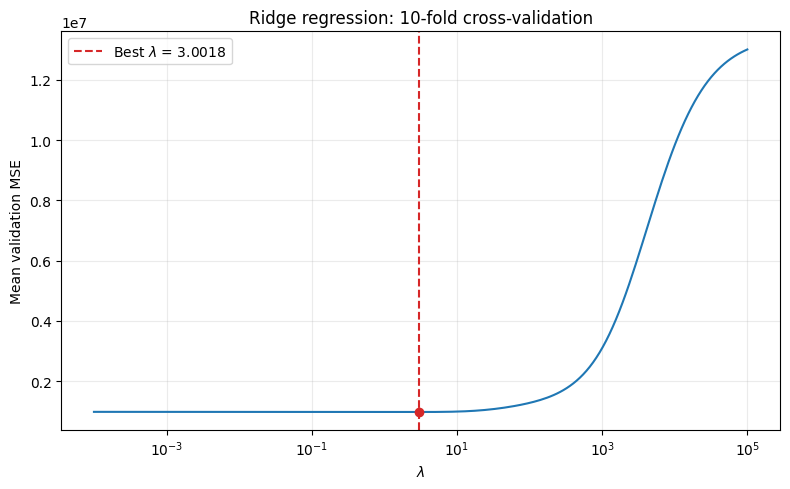

In [37]:
lambda_grid_ridge = np.logspace(-4, 5, 200)

cv9 = KFold(
    n_splits=10,
    shuffle=True,
    random_state=20261028,
)

# 每一折都重新以該折訓練資料估計標準化參數
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge()),
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": lambda_grid_ridge},
    scoring="neg_mean_squared_error",
    cv=cv9,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

ridge_search.fit(X_train, y_train)

best_lambda_ridge = ridge_search.best_params_["model__alpha"]
ridge_cv_mse = -ridge_search.best_score_

# best_estimator_ 已使用最佳參數在完整訓練集上重新配適
ridge_model = ridge_search.best_estimator_
ridge_pred = ridge_model.predict(X_test)

ridge_metrics = regression_metrics(y_test, ridge_pred)

print(f"最佳 lambda：{best_lambda_ridge:.6f}")
print(f"Ridge 十折 CV MSE：{ridge_cv_mse:,.2f}")

# 2. 在相同十折分組下，補充計算 OLS 的 CV MSE
ols_cv_mse = -cross_val_score(
    ols_model,
    X_train,
    y_train,
    scoring="neg_mean_squared_error",
    cv=cv9,
    n_jobs=1,
).mean()

print(f"OLS 十折 CV MSE：{ols_cv_mse:,.2f}")

comparison_9bc = pd.DataFrame({
    "OLS": ols_metrics,
    "Ridge": ridge_metrics,
}).T

print("\n測試集表現比較：")
print(
    comparison_9bc.to_string(
        float_format=lambda value: f"{value:,.4f}"
    )
)

mse_change_pct = 100 * (
    ridge_metrics["Test MSE"] / ols_metrics["Test MSE"] - 1
)

print(f"\nRidge 相對 OLS 的測試 MSE 變化：{mse_change_pct:+.2f}%")

# 3. 檢查訓練資料中的預測變數相關性
print("\n部分預測變數的相關係數（只使用訓練集）：")
print(
    X_train[
        ["Accept", "Enroll", "F.Undergrad"]
    ].corr().round(4)
)

# 4. 分析申請數最高的測試案例
prediction_comparison = pd.DataFrame({
    "Actual": y_test,
    "OLS": ols_pred,
    "Ridge": ridge_pred,
})

prediction_comparison["OLS squared error"] = (
    prediction_comparison["Actual"]
    - prediction_comparison["OLS"]
) ** 2

prediction_comparison["Ridge squared error"] = (
    prediction_comparison["Actual"]
    - prediction_comparison["Ridge"]
) ** 2

largest_idx = y_test.idxmax()

print("\n申請數最高的測試案例：")
print(
    prediction_comparison.loc[[largest_idx]].to_string(
        float_format=lambda value: f"{value:,.2f}"
    )
)

sse_difference = (
    prediction_comparison["Ridge squared error"]
    - prediction_comparison["OLS squared error"]
)

if not np.isclose(sse_difference.sum(), 0):
    contribution = (
        sse_difference.loc[largest_idx]
        / sse_difference.sum()
    )
    print(
        "該案例占兩模型總平方誤差差異的比例："
        f"{contribution:.2%}"
    )

# 5. 繪製 lambda 與交叉驗證 MSE 的關係
ridge_cv_table = pd.DataFrame({
    "lambda": np.asarray(
        ridge_search.cv_results_["param_model__alpha"],
        dtype=float,
    ),
    "CV MSE": -ridge_search.cv_results_["mean_test_score"],
}).sort_values("lambda")

fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogx(
    ridge_cv_table["lambda"],
    ridge_cv_table["CV MSE"],
    color="tab:blue",
)

ax.axvline(
    best_lambda_ridge,
    color="tab:red",
    linestyle="--",
    label=fr"Best $\lambda$ = {best_lambda_ridge:.4f}",
)

ax.scatter(
    best_lambda_ridge,
    ridge_cv_mse,
    color="tab:red",
    zorder=3,
)

ax.set(
    xlabel=r"$\lambda$",
    ylabel="Mean validation MSE",
    title="Ridge regression: 10-fold cross-validation",
)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

### (d) 解釋

先將預測變數標準化，再使用 lasso 配適模型。其目標函數為

$$
\frac{1}{2n_{\mathrm{train}}}
\sum_{i\in\mathrm{train}}
\left(
y_i-\beta_0-\sum_{j=1}^{17}\theta_jz_{ij}
\right)^2
+
\lambda\sum_{j=1}^{17}|\theta_j|,
$$

其中，$z_{ij}$ 為標準化後的預測變數，截距不受懲罰。本文的 $\lambda$ 對應 sklearn 的 `alpha`。

在 $10^{-3}$ 至 $10^4$ 之間設定 200 個對數等距候選值，使用十折交叉驗證選擇平均驗證 MSE 最小的參數。標準化也在每一折的訓練資料內重新估計。

本次結果為：

| 項目 | 結果 |
|---|---:|
| 最佳 $\lambda$ | 6.294989 |
| 十折 CV MSE | 974,436.97 |
| 測試 MSE | 1,888,280.36 |
| 測試 RMSE | 1,374.15 |
| 測試 MAE | 691.57 |
| 測試 $R^2$ | 0.8981 |
| 非零係數數目，不含截距 | 16 |

因此，

$$
\boxed{\operatorname{MSE}_{\mathrm{test}}\approx1,888,280.36},
\qquad
\boxed{\text{非零係數數目}=16}.
$$

17 個預測變數中，只有 `Enroll` 的係數被壓成 0，其餘 16 個變數皆保留。

另外 `Enroll` 與 `Apps` 在訓練集中的相關係數約為 0.883，並不是與申請數沒有關係。然而，`Enroll` 與 `Accept`、`F.Undergrad` 的相關係數分別約為 0.935、0.970，因此它所提供的資訊可能與其他變數重疊。在同時納入其他變數並施加懲罰後，lasso 將其係數壓成 0，不能解讀為 `Enroll` 本身沒有預測能力。

In [38]:
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# 與前面使用相同的十折分組
cv9 = KFold(
    n_splits=10,
    shuffle=True,
    random_state=20261028,
)


def regression_metrics(y_true, y_pred):
    y_pred = np.asarray(y_pred).ravel()
    mse = mean_squared_error(y_true, y_pred)

    return {
        "Test MSE": mse,
        "Test RMSE": np.sqrt(mse),
        "Test MAE": mean_absolute_error(y_true, y_pred),
        "Test R2": r2_score(y_true, y_pred),
    }


lasso_pipeline9 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=200000, tol=1e-8)),
])

lasso_search9 = GridSearchCV(
    estimator=lasso_pipeline9,
    param_grid={
        "model__alpha": np.logspace(-3, 4, 200),
    },
    scoring="neg_mean_squared_error",
    cv=cv9,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

lasso_search9.fit(X_train, y_train)

lasso_model9 = lasso_search9.best_estimator_
lasso_pred9 = lasso_model9.predict(X_test)
lasso_metrics9 = regression_metrics(y_test, lasso_pred9)

scaler9 = lasso_model9.named_steps["scaler"]
lasso9 = lasso_model9.named_steps["model"]

# 用模型實際的零係數判定，不以四捨五入後的數字判定
nonzero9 = lasso9.coef_ != 0
selected9 = X_train.columns[nonzero9].tolist()
removed9 = X_train.columns[~nonzero9].tolist()

# 轉回原始變數尺度，方便解讀係數
raw_coefs9 = lasso9.coef_ / scaler9.scale_
raw_intercept9 = (
    lasso9.intercept_ - np.dot(scaler9.mean_, raw_coefs9)
)

coefficient_table9 = pd.Series(
    np.r_[raw_intercept9, raw_coefs9],
    index=["Intercept"] + X_train.columns.tolist(),
    name="Coefficient",
)

print(
    "最佳 lambda："
    f"{lasso_search9.best_params_['model__alpha']:.6f}"
)
print(f"十折 CV MSE：{-lasso_search9.best_score_:,.2f}")
print(f"非零係數數目，不含截距：{nonzero9.sum()}")
print("保留的變數：", selected9)
print("係數為零的變數：", removed9)

print("\n測試集表現：")
print(pd.Series(lasso_metrics9).round(4))

print("\nEnroll 與其他變數的訓練集相關係數：")
print(pd.Series({
    "Apps": X_train["Enroll"].corr(y_train),
    "Accept": X_train["Enroll"].corr(X_train["Accept"]),
    "F.Undergrad": X_train["Enroll"].corr(X_train["F.Undergrad"]),
}).round(4))

最佳 lambda：6.294989
十折 CV MSE：974,436.97
非零係數數目，不含截距：16
保留的變數： ['Accept', 'Top10perc', 'Top25perc', 'F.Undergrad', 'P.Undergrad', 'Outstate', 'Room.Board', 'Books', 'Personal', 'PhD', 'Terminal', 'S.F.Ratio', 'perc.alumni', 'Expend', 'Grad.Rate', 'Private_Yes']
係數為零的變數： ['Enroll']

測試集表現：
Test MSE     1.888280e+06
Test RMSE    1.374147e+03
Test MAE     6.915705e+02
Test R2      8.981000e-01
dtype: float64

Enroll 與其他變數的訓練集相關係數：
Apps           0.8832
Accept         0.9352
F.Undergrad    0.9702
dtype: float64


### (e) 解答

先將 17 個預測變數標準化，再進行主成分分析，將原始變數轉換成彼此不相關的主成分。接著使用前 $M$ 個主成分配適線性迴歸：

$$
\mathrm{Apps}_i
=
\beta_0+\sum_{m=1}^{M}\gamma_mZ_{im}+\epsilon_i.
$$

主成分依據預測變數的變異大小排序，建立主成分時不使用反應變數 `Apps`。

針對 $M=1,\ldots,17$ 進行十折交叉驗證，並在每一折的訓練資料內重新估計標準化參數、主成分方向及迴歸係數。

本次結果為：

| 項目 | 結果 |
|---|---:|
| 最佳主成分數 $M$ | 17 |
| 十折 CV MSE | 985,794.67 |
| 測試 MSE | 1,861,234.76 |
| 測試 RMSE | 1,364.27 |
| 測試 MAE | 698.32 |
| 測試 $R^2$ | 0.8996 |

因此，

$$
\boxed{M=17},
\qquad
\boxed{\operatorname{MSE}_{\mathrm{test}}\approx1,861,234.76}.
$$

交叉驗證選擇保留全部 17 個主成分，因此本次 PCR 最終沒有降低維度。保留全部主成分相當於對原本的預測變數做可逆的座標轉換，沒有捨棄資訊，所以其預測結果與使用全部變數的最小平方法相同。

另外可以看到在完整訓練集上，前 15 個主成分已解釋約 99.47% 的預測變數總變異，但使用 15 個主成分時，CV MSE 仍約為 1,422,832.44；增加至 16 個後，則降至約 988,600.94。

這說明「解釋大部分預測變數的變異」不等於「保留大部分與反應變數有關的資訊」。排序較後、變異較小的主成分，仍可能包含預測申請數的重要資訊，因此不能只根據累積解釋變異比例決定保留多少主成分。

此外，16 與 17 個主成分的 CV MSE 很接近。本題依最小 CV MSE 選擇 17 個，但不能因此認定 17 個在其他資料分割下也一定最好。

最佳主成分數 M：17
十折 CV MSE：985,794.67

測試集表現：
Test MSE     1.861235e+06
Test RMSE    1.364271e+03
Test MAE     6.983206e+02
Test R2      8.996000e-01
dtype: float64

不同主成分數的交叉驗證結果：
 M        CV MSE
 1 12,422,490.57
 2  2,776,957.94
 3  2,718,697.17
 4  2,592,005.59
 5  1,832,009.66
 6  1,709,938.36
 7  1,673,353.75
 8  1,668,459.49
 9  1,541,263.25
10  1,406,109.30
11  1,402,389.03
12  1,405,872.17
13  1,415,976.17
14  1,415,068.21
15  1,422,831.83
16    988,600.92
17    985,794.67

前 15 個主成分的累積解釋變異比例：99.47%


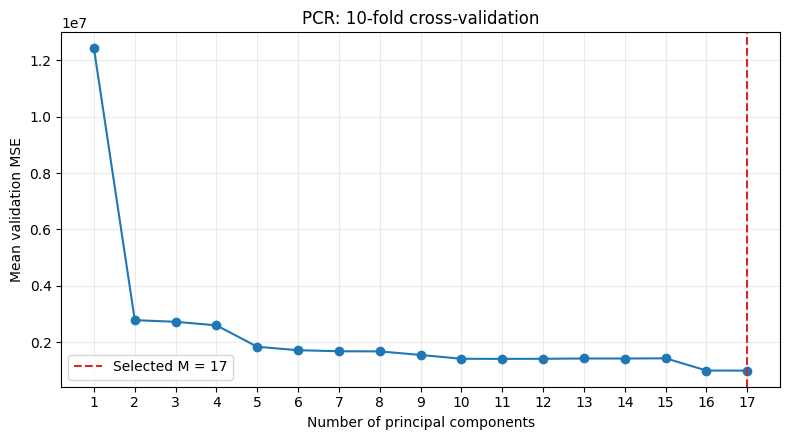

In [39]:
component_grid9 = list(range(1, X_train.shape[1] + 1))

pcr_pipeline9 = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("model", LinearRegression()),
])

pcr_search9 = GridSearchCV(
    estimator=pcr_pipeline9,
    param_grid={
        "pca__n_components": component_grid9,
    },
    scoring="neg_mean_squared_error",
    cv=cv9,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

pcr_search9.fit(X_train, y_train)

pcr_model9 = pcr_search9.best_estimator_
pcr_pred9 = pcr_model9.predict(X_test)
pcr_metrics9 = regression_metrics(y_test, pcr_pred9)

best_m_pcr9 = pcr_search9.best_params_["pca__n_components"]

pcr_cv_table9 = pd.DataFrame({
    "M": np.asarray(
        pcr_search9.cv_results_["param_pca__n_components"],
        dtype=int,
    ),
    "CV MSE": -pcr_search9.cv_results_["mean_test_score"],
}).sort_values("M")

print(f"最佳主成分數 M：{best_m_pcr9}")
print(f"十折 CV MSE：{-pcr_search9.best_score_:,.2f}")

print("\n測試集表現：")
print(pd.Series(pcr_metrics9).round(4))

print("\n不同主成分數的交叉驗證結果：")
print(
    pcr_cv_table9.to_string(
        index=False,
        formatters={"CV MSE": "{:,.2f}".format},
    )
)

# 補充分析：只使用訓練集，檢查累積解釋變異比例
X_train_scaled9 = StandardScaler().fit_transform(X_train)
pca_full9 = PCA(svd_solver="full").fit(X_train_scaled9)

cumulative_variance9 = np.cumsum(
    pca_full9.explained_variance_ratio_
)

print(
    "\n前 15 個主成分的累積解釋變異比例："
    f"{cumulative_variance9[14]:.2%}"
)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    pcr_cv_table9["M"],
    pcr_cv_table9["CV MSE"],
    marker="o",
)
ax.axvline(
    best_m_pcr9,
    color="tab:red",
    linestyle="--",
    label=f"Selected M = {best_m_pcr9}",
)

ax.set(
    xlabel="Number of principal components",
    ylabel="Mean validation MSE",
    title="PCR: 10-fold cross-validation",
)
ax.set_xticks(component_grid9)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

### (f) 解釋

PLS 將原始預測變數組合成新的成分，再利用這些成分預測申請數。

與 PCR 只考慮預測變數本身的變異不同，PLS 在建立成分時，也會考慮其與反應變數 `Apps` 的關係，因此可能用較少的成分保留對預測有用的資訊。

將預測變數標準化後，針對 $M=1,\ldots,17$ 進行十折交叉驗證。每一折的標準化與 PLS 配適，都只使用該折的訓練資料。

本次結果為：

| 項目 | 結果 |
|---|---:|
| 最佳成分數 $M$ | 8 |
| 十折 CV MSE | 984,678.19 |
| 測試 MSE | 1,951,983.76 |
| 測試 RMSE | 1,397.13 |
| 測試 MAE | 701.11 |
| 測試 $R^2$ | 0.8947 |

因此，

$$
\boxed{M=8},
\qquad
\boxed{\operatorname{MSE}_{\mathrm{test}}\approx1,951,983.76}.
$$

相較於 PCR 保留全部 17 個主成分，PLS 使用 8 個成分，就得到相近的交叉驗證誤差，顯示利用反應變數的資訊，確實能在較少成分中保留預測訊息。

不過，8 個成分並不代表只使用 8 個原始變數；每個成分都是原始變數的線性組合，因此 PLS 的降維與 lasso 將部分原始變數係數壓成 0，是不同的做法。

PLS 的測試 MSE 約為 1,951,983.76，高於 PCR 的 1,861,234.76。因此，本次 PLS 雖然使用較少成分，卻沒有得到較低的測試誤差。利用反應變數建立成分，也不保證一定能在新資料上優於 PCR。

另外，PLS 使用 8 與 9 個成分時，CV MSE 分別約為 984,678.19 與 984,791.32，差距僅約 113.13，相對差異約 0.01%。所以差距也不大，所以其實也不能說8摺一定會優於其他折數。

最佳成分數 M：8
十折 CV MSE：984,678.19

測試集表現：
Test MSE     1.951984e+06
Test RMSE    1.397134e+03
Test MAE     7.011051e+02
Test R2      8.947000e-01
dtype: float64

不同成分數的交叉驗證結果：
 M       CV MSE
 1 2,347,364.06
 2 1,781,318.16
 3 1,355,754.03
 4 1,232,297.99
 5 1,136,517.05
 6 1,003,532.75
 7   987,612.20
 8   984,678.19
 9   984,791.30
10   986,189.85
11   990,081.78
12   985,966.82
13   986,670.04
14   985,269.42
15   985,549.17
16   985,745.87
17   985,794.67


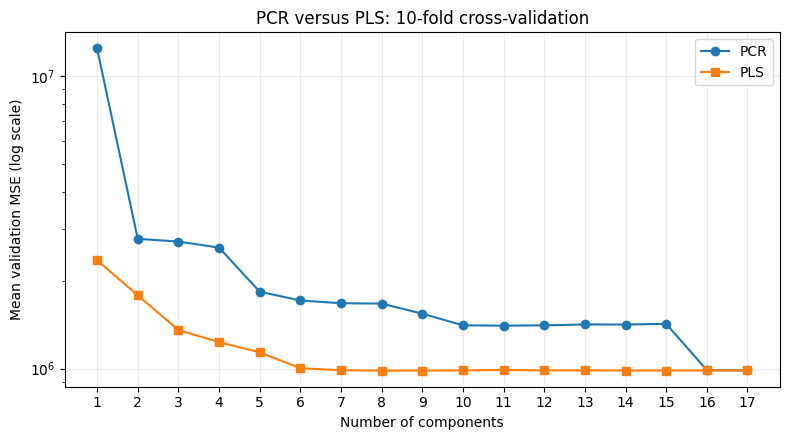


(d)～(f) 測試集結果比較：
            Test MSE  Test RMSE  Test MAE  Test R2
Lasso 1,888,280.3638 1,374.1471  691.5705   0.8981
PCR   1,861,234.7554 1,364.2708  698.3206   0.8996
PLS   1,951,983.7552 1,397.1341  701.1051   0.8947


In [40]:
pls_pipeline9 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", PLSRegression(
        scale=False,
        max_iter=10000,
        tol=1e-10,
    )),
])

pls_search9 = GridSearchCV(
    estimator=pls_pipeline9,
    param_grid={
        "model__n_components": component_grid9,
    },
    scoring="neg_mean_squared_error",
    cv=cv9,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

pls_search9.fit(X_train, y_train)

pls_model9 = pls_search9.best_estimator_
pls_pred9 = np.asarray(
    pls_model9.predict(X_test)
).ravel()

pls_metrics9 = regression_metrics(y_test, pls_pred9)
best_m_pls9 = pls_search9.best_params_["model__n_components"]

pls_cv_table9 = pd.DataFrame({
    "M": np.asarray(
        pls_search9.cv_results_["param_model__n_components"],
        dtype=int,
    ),
    "CV MSE": -pls_search9.cv_results_["mean_test_score"],
}).sort_values("M")

print(f"最佳成分數 M：{best_m_pls9}")
print(f"十折 CV MSE：{-pls_search9.best_score_:,.2f}")

print("\n測試集表現：")
print(pd.Series(pls_metrics9).round(4))

print("\n不同成分數的交叉驗證結果：")
print(
    pls_cv_table9.to_string(
        index=False,
        formatters={"CV MSE": "{:,.2f}".format},
    )
)

# 比較 PCR 與 PLS 在相同十折分組下的驗證誤差
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    pcr_cv_table9["M"],
    pcr_cv_table9["CV MSE"],
    marker="o",
    label="PCR",
)
ax.plot(
    pls_cv_table9["M"],
    pls_cv_table9["CV MSE"],
    marker="s",
    label="PLS",
)

# 對數刻度方便比較不同量級的誤差
ax.set_yscale("log")
ax.set(
    xlabel="Number of components",
    ylabel="Mean validation MSE (log scale)",
    title="PCR versus PLS: 10-fold cross-validation",
)
ax.set_xticks(component_grid9)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

print("\n(d)～(f) 測試集結果比較：")
print(
    pd.DataFrame({
        "Lasso": lasso_metrics9,
        "PCR": pcr_metrics9,
        "PLS": pls_metrics9,
    }).T.to_string(
        float_format=lambda value: f"{value:,.4f}"
    )
)

### (g) 五種模型的結果比較

五種方法使用相同的訓練集與測試集，得到以下結果：

| 方法 | 測試 MSE | 測試 RMSE | 測試 MAE | 測試 $R^2$ |
|---|---:|---:|---:|---:|
| 最小平方法 | 1,861,234.76 | 1,364.27 | 698.32 | 0.8996 |
| Ridge | 1,996,899.07 | 1,413.12 | 704.87 | 0.8923 |
| Lasso | 1,888,280.36 | 1,374.15 | 691.57 | 0.8981 |
| PCR | 1,861,234.76 | 1,364.27 | 698.32 | 0.8996 |
| PLS | 1,951,983.76 | 1,397.13 | 701.11 | 0.8947 |

五種方法的測試 $R^2$ 約為 0.89 至 0.90，表示相較於以測試集平均數作為預測，模型能減少約 89% 至 90% 的平方誤差，具有相當好的整體預測能力。

然而，這不代表每所學校都能準確預測。各模型的 MAE 約為 692 至 705 份申請，而 RMSE 約為 1,364 至 1,413 份。RMSE 明顯高於 MAE，反映部分學校存在較大的預測誤差。

例如，測試集中申請數最高的學校有 48,094 份申請，但五種模型都只預測約 33,613 至 34,674 份，皆明顯低估。因此，模型對整體申請數差異的掌握不錯，但對極高申請數學校的預測仍有限制。

而依測試 MSE，最小平方法與 PCR 最低，接著是 lasso、PLS，最後是 ridge。PCR 因為保留全部 17 個主成分，所以預測結果與最小平方法相同。

相較於最小平方法，lasso、PLS 與 ridge 的測試 MSE 分別高約 1.45%、4.88% 與 7.29%。雖然存在差異，但五種方法的測試 $R^2$ 相差不到 0.01，RMSE 的最大差距也只有約 49 份申請，因此整體預測表現相近。

另外，lasso 的 MAE 最低，但 MSE 並非最低，說明模型排名會受到評估指標影響：MAE 衡量平均絕對誤差，MSE 則更重視少數較大的誤差。

所以根據上述決果，這一題加入懲罰或降低維度，並沒有帶來較低的測試 MSE。

五種模型的測試集表現：
            Test MSE  Test RMSE  Test MAE  Test R2  MSE increase vs OLS (%)
OLS   1,861,234.7554 1,364.2708  698.3206   0.8996                   0.0000
Ridge 1,996,899.0664 1,413.1168  704.8701   0.8923                   7.2889
Lasso 1,888,280.3638 1,374.1471  691.5705   0.8981                   1.4531
PCR   1,861,234.7554 1,364.2708  698.3206   0.8996                  -0.0000
PLS   1,951,983.7552 1,397.1341  701.1051   0.8947                   4.8757

申請數最高的測試案例：
     Actual       OLS     Ridge     Lasso       PCR       PLS
483   48094 34,673.77 33,612.92 34,479.24 34,673.77 34,229.17


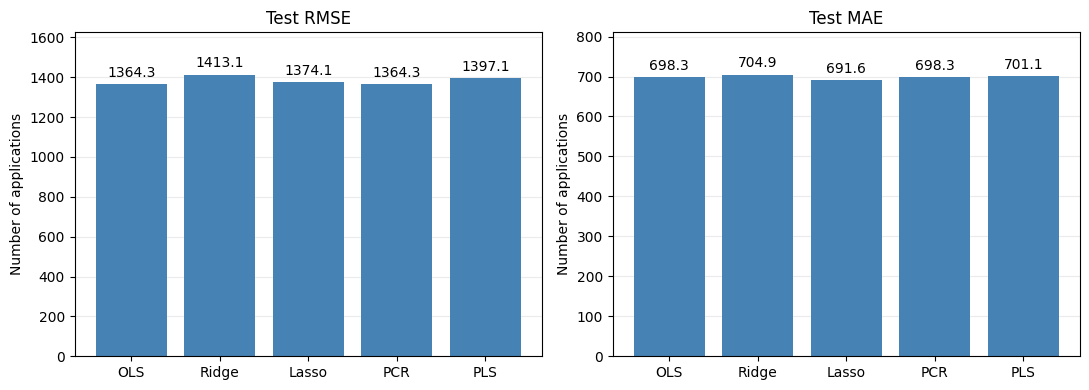

In [41]:
comparison_9g = pd.DataFrame({
    "OLS": ols_metrics,
    "Ridge": ridge_metrics,
    "Lasso": lasso_metrics9,
    "PCR": pcr_metrics9,
    "PLS": pls_metrics9,
}).T

comparison_9g["MSE increase vs OLS (%)"] = (
    comparison_9g["Test MSE"]
    / comparison_9g.loc["OLS", "Test MSE"]
    - 1
) * 100

print("五種模型的測試集表現：")
print(
    comparison_9g.to_string(
        float_format=lambda value: f"{value:,.4f}"
    )
)

# 比較對最高申請數學校的預測
predictions_9g = pd.DataFrame({
    "Actual": y_test,
    "OLS": np.asarray(ols_pred).ravel(),
    "Ridge": np.asarray(ridge_pred).ravel(),
    "Lasso": np.asarray(lasso_pred9).ravel(),
    "PCR": np.asarray(pcr_pred9).ravel(),
    "PLS": np.asarray(pls_pred9).ravel(),
})

print("\n申請數最高的測試案例：")
print(
    predictions_9g.loc[[y_test.idxmax()]].to_string(
        float_format=lambda value: f"{value:,.2f}"
    )
)

# 同時比較 RMSE 與 MAE，觀察評估指標對排名的影響
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, metric in zip(
    axes,
    ["Test RMSE", "Test MAE"],
):
    values = comparison_9g[metric]

    bars = ax.bar(
        comparison_9g.index,
        values,
        color="steelblue",
    )

    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set(
        title=metric,
        ylabel="Number of applications",
        ylim=(0, values.max() * 1.15),
    )
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()